### ML Lab 9
#### Name: Shubhangi Verma
#### Section: C-C4
#### Roll no.: 51


In [9]:
import warnings
warnings.filterwarnings('ignore')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.cluster.hierarchy import fcluster

sns.set_theme(style='whitegrid')
plt.rcParams["figure.figsize"] = (8,5)

In [10]:
from google.colab import files
uploaded = files.upload()

Saving Wholesale customers data - Wholesale customers data.csv to Wholesale customers data - Wholesale customers data (1).csv


In [11]:

df=pd.read_csv("Wholesale customers data - Wholesale customers data.csv")

In [12]:
df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [13]:
df.tail()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
435,1,3,29703,12051,16027,13135,182,2204
436,1,3,39228,1431,764,4510,93,2346
437,2,3,14531,15488,30243,437,14841,1867
438,1,3,10290,1981,2232,1038,168,2125
439,1,3,2787,1698,2510,65,477,52


In [14]:
df.shape

(440, 8)

In [15]:
df.isnull().sum()

,0
Channel,0
Region,0
Fresh,0
Milk,0
Grocery,0
Frozen,0
Detergents_Paper,0
Delicassen,0


In [16]:
df.info

<bound method DataFrame.info of      Channel  Region  Fresh   Milk  Grocery  Frozen  Detergents_Paper  \
0          2       3  12669   9656     7561     214              2674   
1          2       3   7057   9810     9568    1762              3293   
2          2       3   6353   8808     7684    2405              3516   
3          1       3  13265   1196     4221    6404               507   
4          2       3  22615   5410     7198    3915              1777   
..       ...     ...    ...    ...      ...     ...               ...   
435        1       3  29703  12051    16027   13135               182   
436        1       3  39228   1431      764    4510                93   
437        2       3  14531  15488    30243     437             14841   
438        1       3  10290   1981     2232    1038               168   
439        1       3   2787   1698     2510      65               477   

     Delicassen  
0          1338  
1          1776  
2          7844  
3          1788  
4          5185  
..          ...  
435        2204  
436        2346  
437        1867  
438        2125  
439          52  

[440 rows x 8 columns]>

In [17]:
df.describe()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,1.322727,2.543182,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,0.468052,0.774272,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,1.000000,1.000000,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,1.000000,2.000000,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,1.000000,3.000000,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,2.000000,3.000000,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,2.000000,3.000000,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


In [18]:
df.duplicated().sum()

np.int64(0)

In [19]:
df.drop_duplicates(inplace=True)

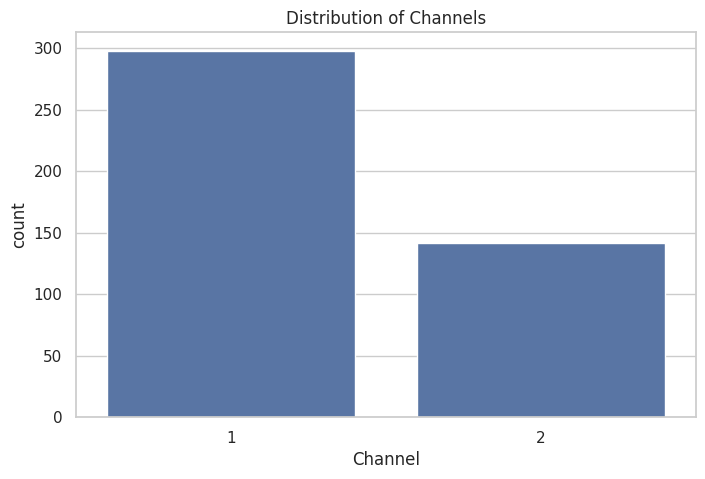

In [21]:
sns.countplot(x='Channel', data=df)
plt.title('Distribution of Channels')
plt.show()

Algorithm

In [22]:
# Define features to be scaled (spending categories)
features = ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']
X = df[features]

# Standardize the six spending features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [23]:
#Convert scaled values into a dataframe for easier inspection
X_scaled_df=pd.DataFrame(X_scaled,columns=features,index=X.index)

In [24]:
print("First 5 scaled records:")
display(X_scaled_df.head)

First 5 scaled records:


<bound method NDFrame.head of         Fresh      Milk   Grocery    Frozen  Detergents_Paper  Delicassen
0    0.052933  0.523568 -0.041115 -0.589367         -0.043569   -0.066339
1   -0.391302  0.544458  0.170318 -0.270136          0.086407    0.089151
2   -0.447029  0.408538 -0.028157 -0.137536          0.133232    2.243293
3    0.100111 -0.624020 -0.392977  0.687144         -0.498588    0.093411
4    0.840239 -0.052396 -0.079356  0.173859         -0.231918    1.299347
..        ...       ...       ...       ...               ...         ...
435  1.401312  0.848446  0.850760  2.075222         -0.566831    0.241091
436  2.155293 -0.592142 -0.757165  0.296561         -0.585519    0.291501
437  0.200326  1.314671  2.348386 -0.543380          2.511218    0.121456
438 -0.135384 -0.517536 -0.602514 -0.419441         -0.569770    0.213046
439 -0.729307 -0.555924 -0.573227 -0.620094         -0.504888   -0.522869

[440 rows x 6 columns]>

In [25]:
print("\nScaled feature means:")
print(X_scaled_df.mean().round(3))


Scaled feature means:
Fresh              -0.0
Milk                0.0
Grocery            -0.0
Frozen              0.0
Detergents_Paper    0.0
Delicassen         -0.0
dtype: float64


In [26]:
print("\nScaled feature standard deviations(approx. one):")
print(X_scaled_df.std(ddof=0).round(3))


Scaled feature standard deviations(approx. one):
Fresh               1.0
Milk                1.0
Grocery             1.0
Frozen              1.0
Detergents_Paper    1.0
Delicassen          1.0
dtype: float64


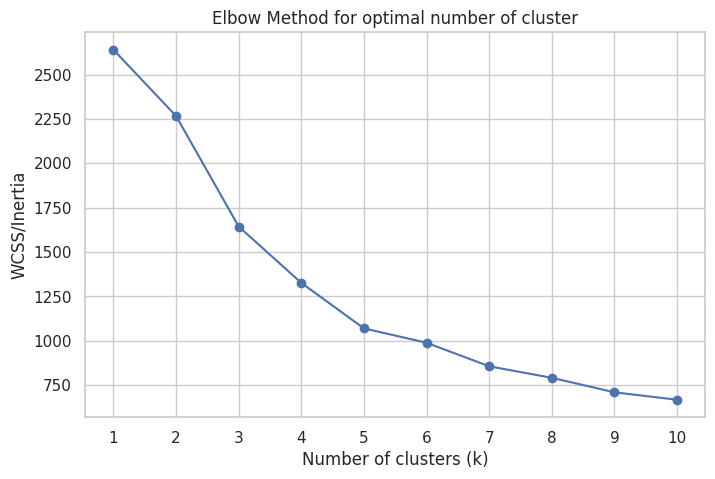

In [27]:
# Calculate WCSS (Within-cluster sum of squares)
wcss=[]
k_values=range(1,11)

for k in k_values:
    kmeans=KMeans(n_clusters=k,random_state=42)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

#plot
plt.figure(figsize=(8,5))
plt.plot(list(k_values),wcss,marker="o")
plt.title("Elbow Method for optimal number of cluster")
plt.xlabel("Number of clusters (k)")
plt.ylabel("WCSS/Inertia")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

In [29]:
#Calculate silhouette scores to support the elbow detection
silhouette_scores = []
# Silhouette score requires at least 2 clusters to be calculated
k_values_silhouette = range(2, 11)

for k in k_values_silhouette:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

silhouette_table = pd.DataFrame({
    "Number of Clusters (k)": k_values_silhouette,
    "Silhouette Score": silhouette_scores
})

display(silhouette_table.round(4))

,Number of Clusters (k),Silhouette Score
0,2,0.5472
1,3,0.5483
2,4,0.3485
3,5,0.3690
4,6,0.3782
5,7,0.3343
6,8,0.3201
7,9,0.3090
8,10,0.3112


In [30]:
suggested_k=int(
    silhouette_table.loc[silhouette_table["Silhouette Score"].idxmax(),"Number of Clusters (k)"]
)

print("K suggested by the highest silhouette score:",suggested_k)

K suggested by the highest silhouette score: 3


In [33]:
K = suggested_k

kmeans_model = KMeans(n_clusters=K, random_state=42, n_init=10)
kmeans_labels = kmeans_model.fit_predict(X_scaled)

In [42]:
# add cluster label to a copy of the original dataset
df_kmeans = df.copy()
df_kmeans["KMeans_Cluster"] = kmeans_labels

print("KMeans clustering completed.")
print("\nNumber of customers in each cluster:")
print(df_kmeans["KMeans_Cluster"].value_counts().sort_index())

print("\nFirst 5 rows of the dataset with cluster labels:")
display(df_kmeans.head())

KMeans clustering completed.

Number of customers in each cluster:
KMeans_Cluster
0     45
1    393
2      2
Name: count, dtype: int64

First 5 rows of the dataset with cluster labels:


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,KMeans_Cluster
0,2,3,12669,9656,7561,214,2674,1338,1
1,2,3,7057,9810,9568,1762,3293,1776,1
2,2,3,6353,8808,7684,2405,3516,7844,1
3,1,3,13265,1196,4221,6404,507,1788,1
4,2,3,22615,5410,7198,3915,1777,5185,1


In [45]:
#build the hierarchical clustering model
hierarchical_model=AgglomerativeClustering(n_clusters=K,metric="euclidean",linkage="ward")
hierarchical_labels=hierarchical_model.fit_predict(X_scaled)

In [46]:
# store the cluster labels
df_hierarchical = df.copy()
df_hierarchical["Hierarchical_Cluster"] = hierarchical_labels

print("Hierarchical clustering completed.")
print("\nNumber of customers in each cluster:")
print(df_hierarchical["Hierarchical_Cluster"].value_counts().sort_index())

print("\nFirst 5 rows of the dataset with cluster labels:")
display(df_hierarchical.head())

Hierarchical clustering completed.

Number of customers in each cluster:
Hierarchical_Cluster
0      6
1    281
2    153
Name: count, dtype: int64

First 5 rows of the dataset with cluster labels:


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Hierarchical_Cluster
0,2,3,12669,9656,7561,214,2674,1338,2
1,2,3,7057,9810,9568,1762,3293,1776,2
2,2,3,6353,8808,7684,2405,3516,7844,2
3,1,3,13265,1196,4221,6404,507,1788,1
4,2,3,22615,5410,7198,3915,1777,5185,1


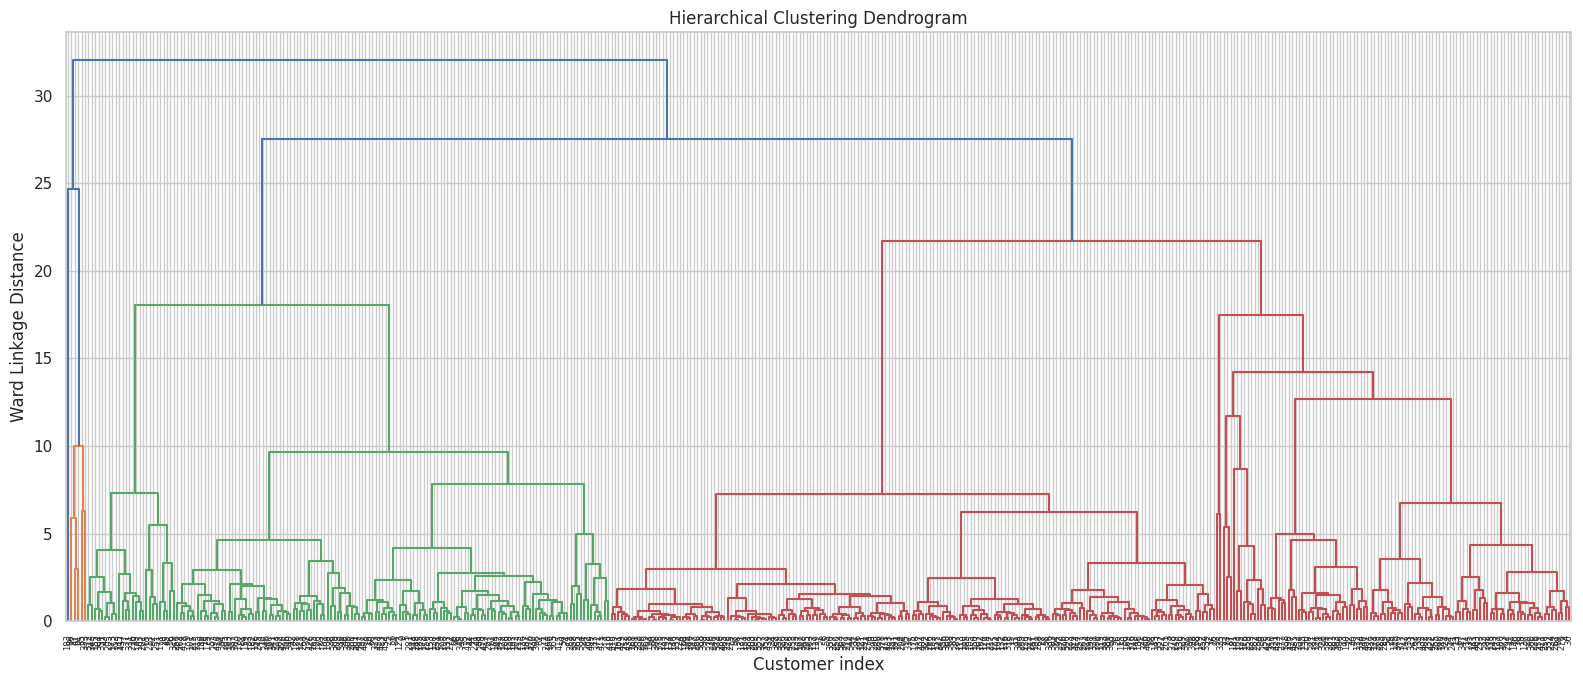

In [36]:
Z = linkage(X_scaled, method="ward", metric="euclidean")

plt.figure(figsize=(16,7))
dendrogram(Z, leaf_rotation=90, leaf_font_size=6)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Customer index")
plt.ylabel("Ward Linkage Distance")
plt.tight_layout()
plt.show()

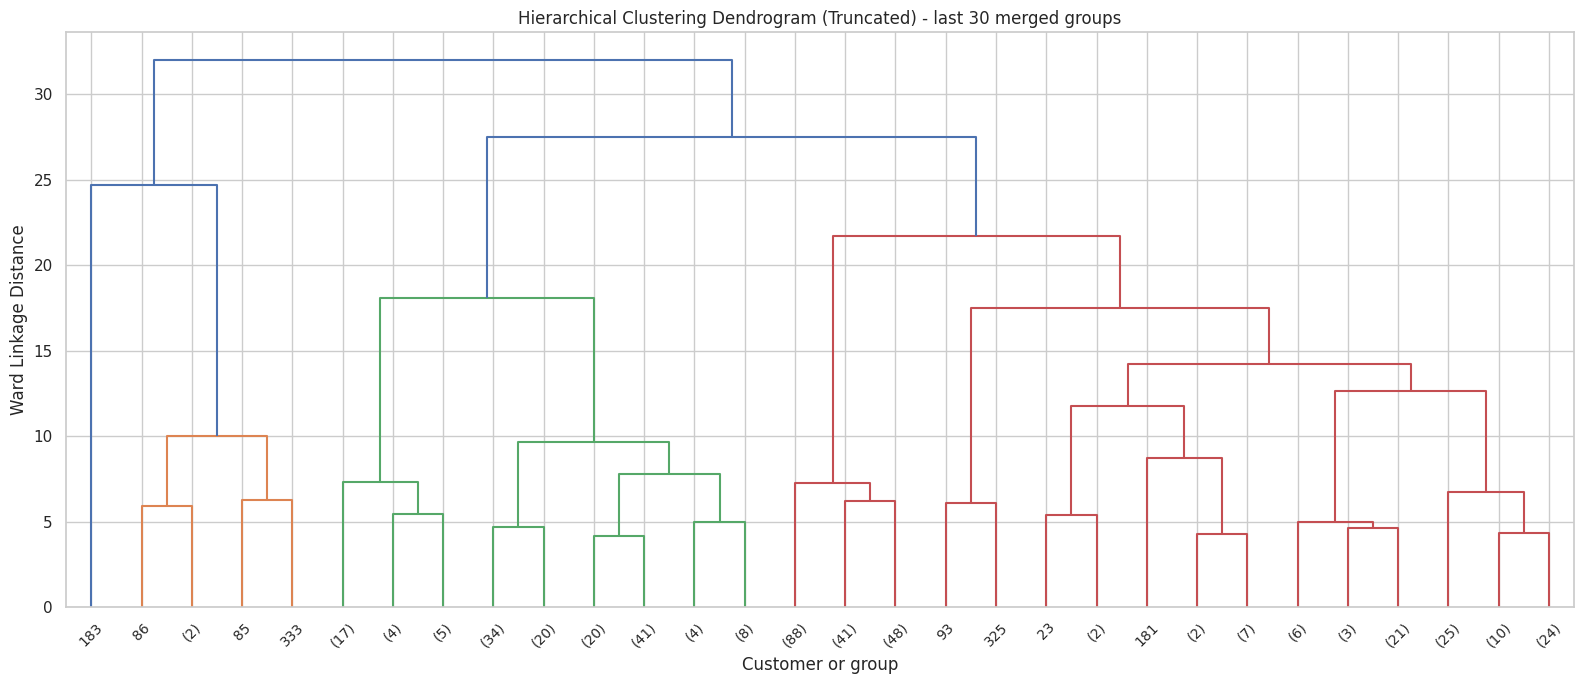

In [37]:
# truncated dendrogram for easier interpretation
plt.figure(figsize=(16,7))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=45, show_leaf_counts=True, leaf_font_size=10)

plt.title("Hierarchical Clustering Dendrogram (Truncated) - last 30 merged groups")
plt.xlabel("Customer or group")
plt.ylabel("Ward Linkage Distance")
plt.tight_layout()
plt.show()

In [47]:
# reduce six scaled features to two principal components
pca = PCA(n_components=2)
X_PCA = pca.fit_transform(X_scaled)
print(
    "Variance explained by the 2 PCA components:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

# create a plotting dataframe
plot_df = pd.DataFrame({
    "PC1": X_PCA[:, 0],
    "PC2": X_PCA[:, 1],
    "KMeans_Cluster": kmeans_labels.astype(str),
    "Hierarchical_Cluster": hierarchical_labels.astype(str)
})

Variance explained by the 2 PCA components: 72.46 %


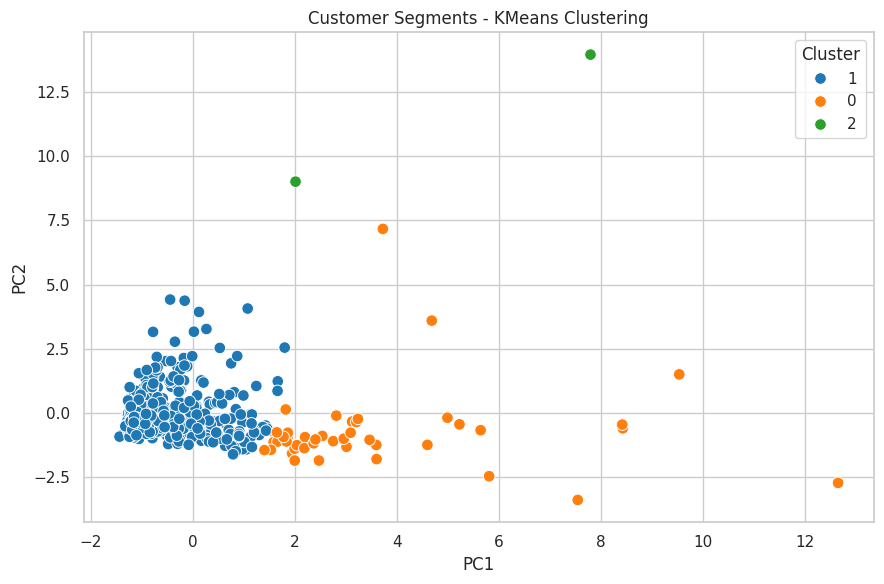

In [48]:
# kmeans visualization
plt.figure(figsize=(9,6))
sns.scatterplot(data=plot_df, x="PC1", y="PC2", hue="KMeans_Cluster", palette="tab10", s=70)

plt.title("Customer Segments - KMeans Clustering")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

In [49]:
# function to calculate clustering evaluation metrics
def evaluate_clustering(X_data, labels, model_name):
    return {
        "Algorithm": model_name,
        "Number of Clusters": len(np.unique(labels)),
        "Silhouette Score": silhouette_score(X_data, labels)
    }

In [50]:
# evaluate both models using the same scaled features
comparison = pd.DataFrame([
    evaluate_clustering(X_scaled, kmeans_labels, "KMeans"),
    evaluate_clustering(X_scaled, hierarchical_labels, "Hierarchical")
])

print("Comparison of clustering algorithms:")
display(comparison.round(4))

Comparison of clustering algorithms:


,Algorithm,Number of Clusters,Silhouette Score
0,KMeans,3,0.5483
1,Hierarchical,3,0.2646
